In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import zipfile
import os

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

In [ ]:
from google.colab import files

uploaded = files.upload()

Saving kaggleusedcar.zip to kaggleusedcar.zip


In [ ]:
zip_path = next(name for name in uploaded if name.endswith(".zip"))

with zipfile.ZipFile(zip_path, "r") as z:
    csv_files = [name for name in z.namelist() if name.lower().endswith(".csv")]
    print(csv_files)
    with z.open(csv_files[0]) as f:
        df = pd.read_csv(f)

df.head()

['car data.csv']


,Car_Name,Year,Selling_Price,Present_Price,Driven_kms,Fuel_Type,Selling_type,Transmission,Owner
0,ritz,2014,3.35,5.59,27000,Petrol,Dealer,Manual,0
1,sx4,2013,4.75,9.54,43000,Diesel,Dealer,Manual,0
2,ciaz,2017,7.25,9.85,6900,Petrol,Dealer,Manual,0
3,wagon r,2011,2.85,4.15,5200,Petrol,Dealer,Manual,0
4,swift,2014,4.60,6.87,42450,Diesel,Dealer,Manual,0


In [ ]:
print("Dataset Shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())
print("\nDataset Information:")
df.info()
print("\nMissing Values:")
print(df.isnull().sum())
print("\nStatistical Summary:")
display(df.describe(include="all").T)

Dataset Shape: (301, 9)

Columns:
['Car_Name', 'Year', 'Selling_Price', 'Present_Price', 'Driven_kms', 'Fuel_Type', 'Selling_type', 'Transmission', 'Owner']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 301 entries, 0 to 300
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Car_Name       301 non-null    object 
 1   Year           301 non-null    int64  
 2   Selling_Price  301 non-null    float64
 3   Present_Price  301 non-null    float64
 4   Driven_kms     301 non-null    int64  
 5   Fuel_Type      301 non-null    object 
 6   Selling_type   301 non-null    object 
 7   Transmission   301 non-null    object 
 8   Owner          301 non-null    int64  
dtypes: float64(2), int64(3), object(4)
memory usage: 21.3+ KB

Missing Values:
Car_Name         0
Year             0
Selling_Price    0
Present_Price    0
Driven_kms       0
Fuel_Type        0
Selling_type     0
Transmission     0
O

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Car_Name,301,98,city,26,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Year,301.0,NaN,NaN,NaN,2013.627907,2.891554,2003.0,2012.0,2014.0,2016.0,2018.0
Selling_Price,301.0,NaN,NaN,NaN,4.661296,5.082812,0.1,0.9,3.6,6.0,35.0
Present_Price,301.0,NaN,NaN,NaN,7.628472,8.642584,0.32,1.2,6.4,9.9,92.6
Driven_kms,301.0,NaN,NaN,NaN,36947.20598,38886.883882,500.0,15000.0,32000.0,48767.0,500000.0
Fuel_Type,301,3,Petrol,239,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Selling_type,301,2,Dealer,195,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Transmission,301,2,Manual,261,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Owner,301.0,NaN,NaN,NaN,0.043189,0.247915,0.0,0.0,0.0,0.0,3.0


In [ ]:
df.columns = df.columns.str.strip()
df = df.drop_duplicates()
df = df.dropna(subset=["Selling_Price"])
df = df[df["Selling_Price"] > 0]
df = df[df["Present_Price"] > 0]

df["Car_Age"] = 2026 - df["Year"]
df["Brand"] = df["Car_Name"].astype(str).str.strip().str.lower().str.split().str[0]
df["Kilometers_Per_Year"] = df["Driven_kms"] / df["Car_Age"].clip(lower=1)

df = df.drop(columns=["Car_Name", "Year"])

display(df.head())
print("Cleaned Dataset Shape:", df.shape)

,Selling_Price,Present_Price,Driven_kms,Fuel_Type,Selling_type,Transmission,Owner,Car_Age,Brand,Kilometers_Per_Year
0,3.35,5.59,27000,Petrol,Dealer,Manual,0,12,ritz,2250.000000
1,4.75,9.54,43000,Diesel,Dealer,Manual,0,13,sx4,3307.692308
2,7.25,9.85,6900,Petrol,Dealer,Manual,0,9,ciaz,766.666667
3,2.85,4.15,5200,Petrol,Dealer,Manual,0,15,wagon,346.666667
4,4.60,6.87,42450,Diesel,Dealer,Manual,0,12,swift,3537.500000


Cleaned Dataset Shape: (299, 10)


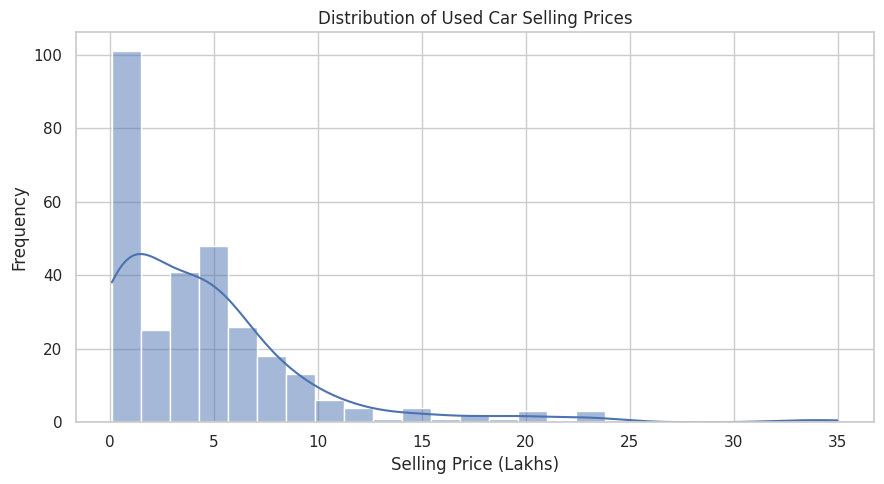

In [ ]:
plt.figure(figsize=(9, 5))
sns.histplot(df["Selling_Price"], kde=True, bins=25)
plt.title("Distribution of Used Car Selling Prices")
plt.xlabel("Selling Price (Lakhs)")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

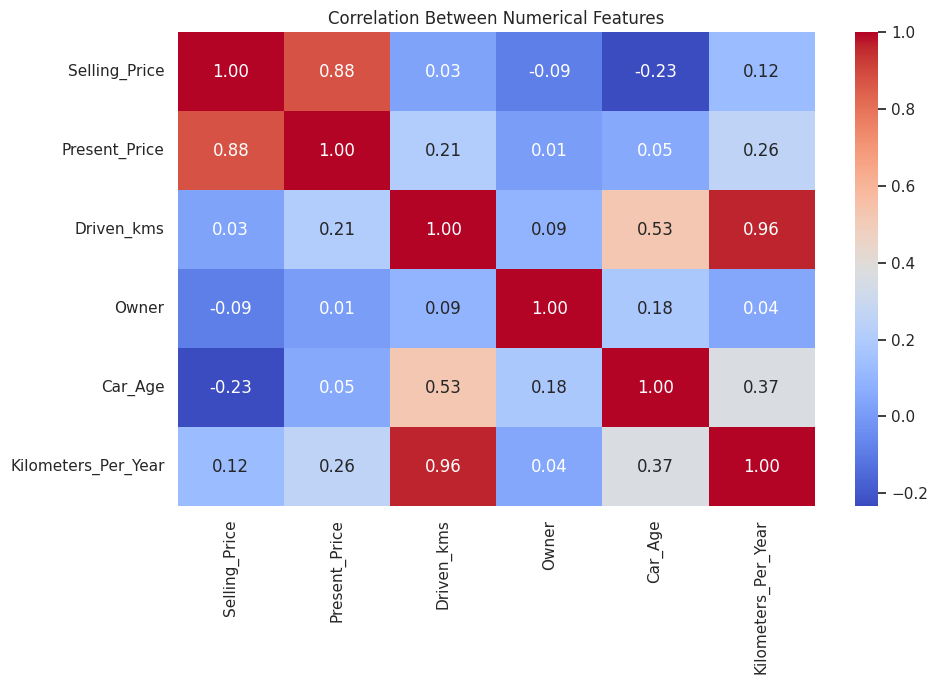

In [ ]:
plt.figure(figsize=(10, 7))
numeric_df = df.select_dtypes(include=np.number)
sns.heatmap(numeric_df.corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Between Numerical Features")
plt.tight_layout()
plt.show()

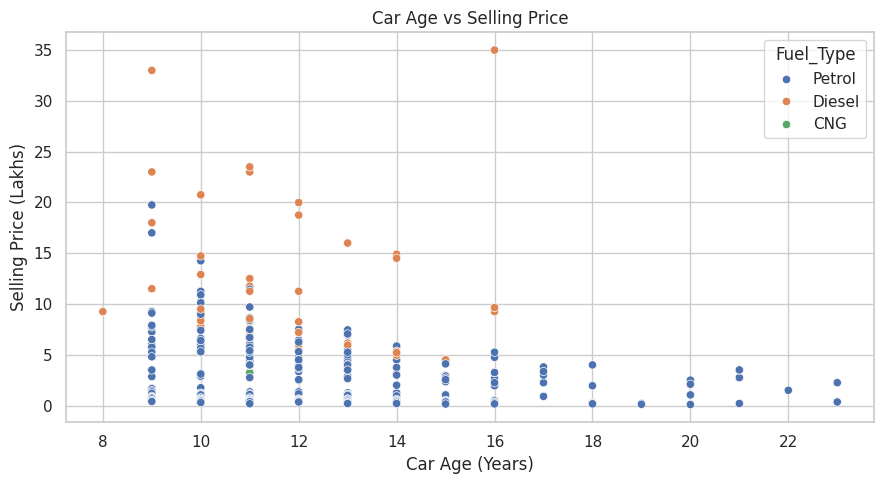

In [ ]:
plt.figure(figsize=(9, 5))
sns.scatterplot(data=df, x="Car_Age", y="Selling_Price", hue="Fuel_Type")
plt.title("Car Age vs Selling Price")
plt.xlabel("Car Age (Years)")
plt.ylabel("Selling Price (Lakhs)")
plt.tight_layout()
plt.show()

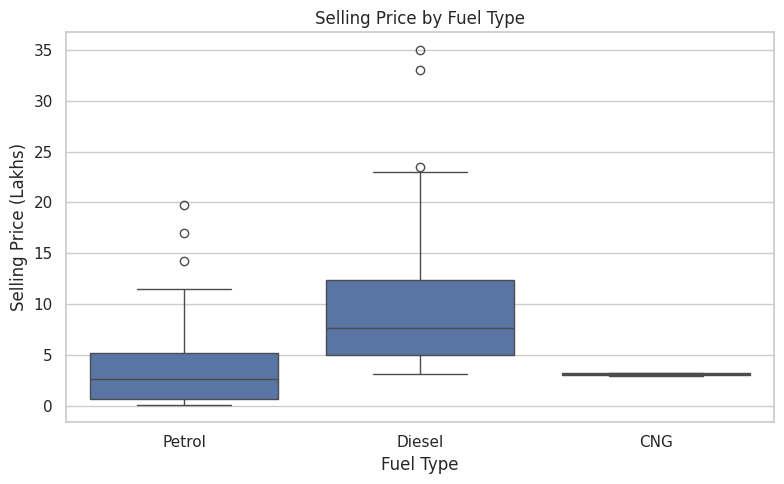

In [ ]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="Fuel_Type", y="Selling_Price")
plt.title("Selling Price by Fuel Type")
plt.xlabel("Fuel Type")
plt.ylabel("Selling Price (Lakhs)")
plt.tight_layout()
plt.show()

In [ ]:
X = df.drop(columns=["Selling_Price"])
y = df["Selling_Price"]

categorical_features = X.select_dtypes(include=["object"]).columns.tolist()
numerical_features = X.select_dtypes(exclude=["object"]).columns.tolist()

print("Numerical Features:", numerical_features)
print("Categorical Features:", categorical_features)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training Samples:", X_train.shape[0])
print("Testing Samples:", X_test.shape[0])

Numerical Features: ['Present_Price', 'Driven_kms', 'Owner', 'Car_Age', 'Kilometers_Per_Year']
Categorical Features: ['Fuel_Type', 'Selling_type', 'Transmission', 'Brand']
Training Samples: 239
Testing Samples: 60


In [ ]:
numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numeric_transformer, numerical_features),
    ("cat", categorical_transformer, categorical_features)
])

In [ ]:
models = {
    "Linear Regression": LinearRegression(),
    "Ridge Regression": Ridge(alpha=1.0),
    "Random Forest": RandomForestRegressor(
        n_estimators=200, random_state=42, min_samples_leaf=2
    ),
    "Gradient Boosting": GradientBoostingRegressor(
        n_estimators=100, learning_rate=0.05, max_depth=2, random_state=42
    )
}

results = []
trained_models = {}

for name, model in models.items():
    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("model", model)
    ])

    pipeline.fit(X_train, y_train)
    predictions = pipeline.predict(X_test)

    results.append({
        "Model": name,
        "MAE": mean_absolute_error(y_test, predictions),
        "RMSE": np.sqrt(mean_squared_error(y_test, predictions)),
        "R2 Score": r2_score(y_test, predictions)
    })

    trained_models[name] = pipeline

results_df = pd.DataFrame(results).sort_values("RMSE").reset_index(drop=True)
display(results_df.round(3))

,Model,MAE,RMSE,R2 Score
0,Ridge Regression,1.366,2.496,0.758
1,Linear Regression,1.481,2.826,0.690
2,Gradient Boosting,1.459,3.027,0.645
3,Random Forest,1.397,3.387,0.555


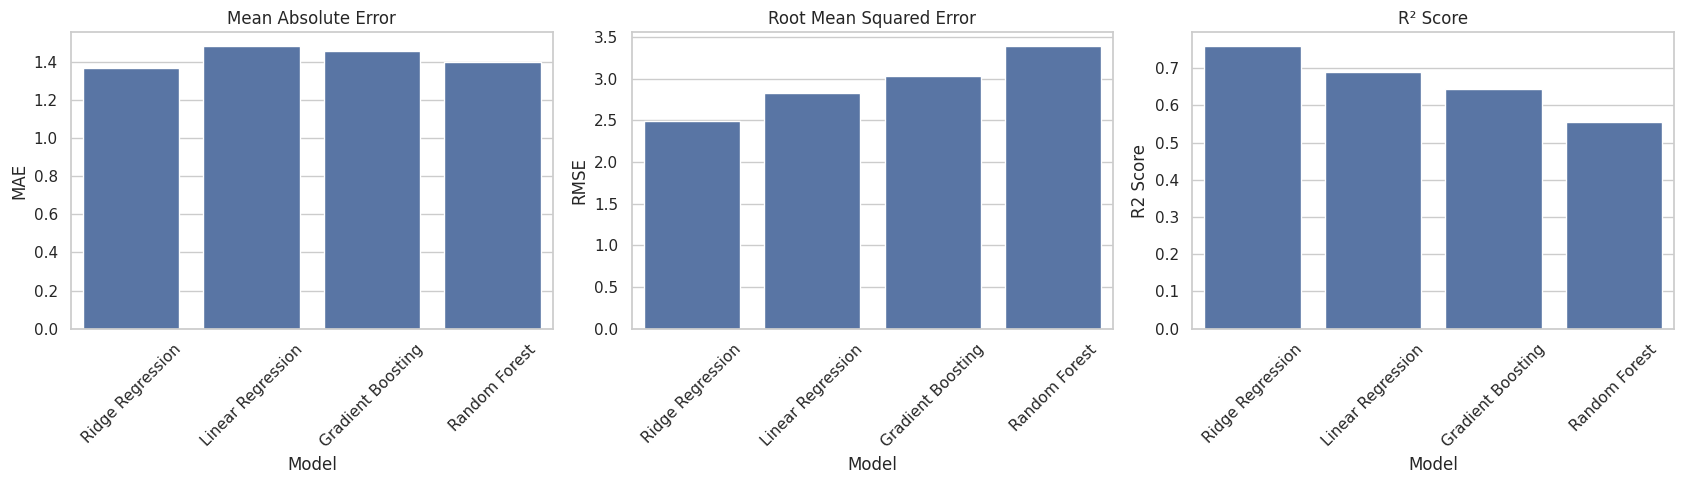

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))

sns.barplot(data=results_df, x="Model", y="MAE", ax=axes[0])
axes[0].set_title("Mean Absolute Error")
axes[0].tick_params(axis="x", rotation=45)

sns.barplot(data=results_df, x="Model", y="RMSE", ax=axes[1])
axes[1].set_title("Root Mean Squared Error")
axes[1].tick_params(axis="x", rotation=45)

sns.barplot(data=results_df, x="Model", y="R2 Score", ax=axes[2])
axes[2].set_title("R² Score")
axes[2].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

In [ ]:
best_model_name = results_df.iloc[0]["Model"]
best_model = trained_models[best_model_name]

print("Best Model:", best_model_name)
print("MAE:", round(results_df.iloc[0]["MAE"], 3), "Lakhs")
print("RMSE:", round(results_df.iloc[0]["RMSE"], 3), "Lakhs")
print("R² Score:", round(results_df.iloc[0]["R2 Score"], 3))

Best Model: Ridge Regression
MAE: 1.366 Lakhs
RMSE: 2.496 Lakhs
R² Score: 0.758


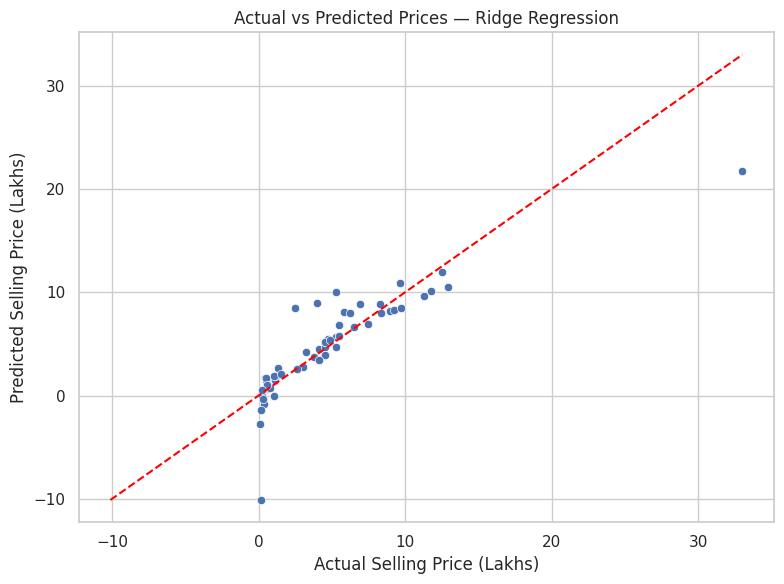

In [ ]:
predictions = best_model.predict(X_test)

plt.figure(figsize=(8, 6))
sns.scatterplot(x=y_test, y=predictions)
lower = min(y_test.min(), predictions.min())
upper = max(y_test.max(), predictions.max())
plt.plot([lower, upper], [lower, upper], linestyle="--", color="red")
plt.xlabel("Actual Selling Price (Lakhs)")
plt.ylabel("Predicted Selling Price (Lakhs)")
plt.title(f"Actual vs Predicted Prices — {best_model_name}")
plt.tight_layout()
plt.show()

,Actual Price,Predicted Price,Error
0,8.99,8.16,0.83
1,8.35,8.01,0.34
2,0.45,1.72,-1.27
3,7.45,6.92,0.53
4,5.25,9.98,-4.73
5,5.25,4.68,0.57
6,5.85,8.08,-2.23
7,1.15,1.89,-0.74
8,9.25,8.31,0.94
9,0.38,-0.82,1.20


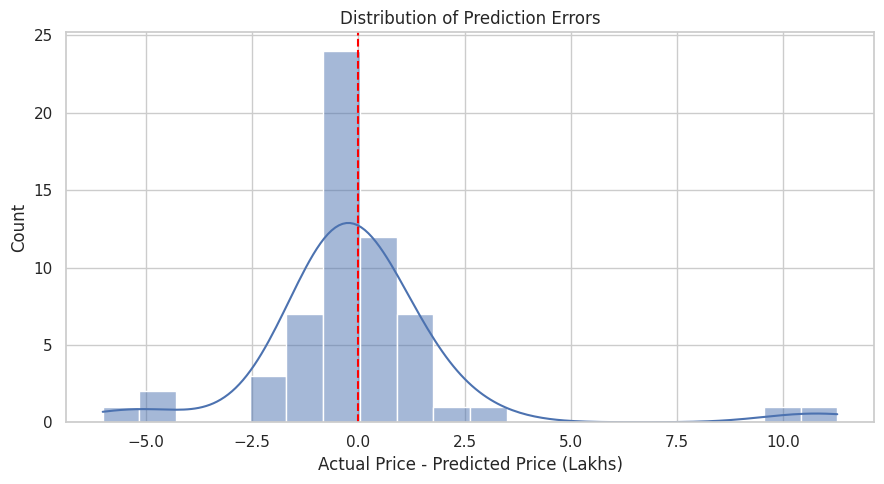

In [ ]:
prediction_results = pd.DataFrame({
    "Actual Price": y_test.values,
    "Predicted Price": predictions,
    "Error": y_test.values - predictions
})

display(prediction_results.head(10).round(2))

plt.figure(figsize=(9, 5))
sns.histplot(prediction_results["Error"], kde=True, bins=20)
plt.axvline(0, color="red", linestyle="--")
plt.title("Distribution of Prediction Errors")
plt.xlabel("Actual Price - Predicted Price (Lakhs)")
plt.tight_layout()
plt.show()

In [ ]:
import ipywidgets as widgets
from IPython.display import display, clear_output

brand_widget = widgets.Dropdown(
    options=sorted(df["Brand"].unique()),
    description="Brand:"
)

fuel_widget = widgets.Dropdown(
    options=sorted(df["Fuel_Type"].unique()),
    description="Fuel:"
)

seller_widget = widgets.Dropdown(
    options=sorted(df["Selling_type"].unique()),
    description="Seller:"
)

transmission_widget = widgets.Dropdown(
    options=sorted(df["Transmission"].unique()),
    description="Gearbox:"
)

present_price_widget = widgets.FloatSlider(
    value=float(df["Present_Price"].median()),
    min=float(df["Present_Price"].min()),
    max=float(df["Present_Price"].max()),
    step=0.1,
    description="New Price:"
)

age_widget = widgets.IntSlider(
    value=int(df["Car_Age"].median()),
    min=0,
    max=30,
    description="Age:"
)

kms_widget = widgets.IntSlider(
    value=int(df["Driven_kms"].median()),
    min=0,
    max=300000,
    step=1000,
    description="Kilometers:"
)

owner_widget = widgets.IntSlider(
    value=0,
    min=0,
    max=3,
    description="Owners:"
)

predict_button = widgets.Button(
    description="Predict Car Price",
    button_style="success"
)

output = widgets.Output()

def predict_car_price(button):
    with output:
        clear_output(wait=True)

        car_age = age_widget.value
        driven_kms = kms_widget.value

        input_data = pd.DataFrame([{
            "Present_Price": present_price_widget.value,
            "Driven_kms": driven_kms,
            "Fuel_Type": fuel_widget.value,
            "Selling_type": seller_widget.value,
            "Transmission": transmission_widget.value,
            "Owner": owner_widget.value,
            "Car_Age": car_age,
            "Brand": brand_widget.value,
            "Kilometers_Per_Year": driven_kms / max(car_age, 1)
        }])

        predicted_price = best_model.predict(input_data)[0]

        print(f"Estimated Selling Price: ₹{predicted_price:.2f} Lakhs")

predict_button.on_click(predict_car_price)

display(widgets.VBox([
    brand_widget,
    fuel_widget,
    seller_widget,
    transmission_widget,
    present_price_widget,
    age_widget,
    kms_widget,
    owner_widget,
    predict_button,
    output
]))

In [ ]:
import joblib

joblib.dump(best_model, "car_price_prediction_model.pkl")

files.download("car_price_prediction_model.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
print("CAR PRICE PREDICTION PROJECT")
print("=" * 40)
print("Dataset Records:", len(df))
print("Features Used:", len(X.columns))
print("Models Evaluated:", len(trained_models))
print("Selected Model:", best_model_name)
print("Mean Absolute Error:", round(results_df.iloc[0]["MAE"], 3), "Lakhs")
print("Root Mean Squared Error:", round(results_df.iloc[0]["RMSE"], 3), "Lakhs")
print("R2 Score:", round(results_df.iloc[0]["R2 Score"], 3))
print("=" * 40)
print("Project Completed Successfully")

CAR PRICE PREDICTION PROJECT
Dataset Records: 299
Features Used: 9
Models Evaluated: 4
Selected Model: Ridge Regression
Mean Absolute Error: 1.366 Lakhs
Root Mean Squared Error: 2.496 Lakhs
R2 Score: 0.758
Project Completed Successfully
